In [9]:
import numpy as np, pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score,
                             recall_score, f1_score, confusion_matrix, roc_curve)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
DATA_PATH = "nscg2023_onet30_2_integration63.csv"

**Part 1: Setup**
JOBSATIS
*   1 = very satisfied
*   2 = somewhat satisfied
*   3 = somewhat dissatisfied
*   4 = very dissatisfied


Based of these values, we changed them into a yes/no model: satisfied = 1 or 2 and unsatisfied = 3 or 4.

The occupation code is being kept as groups to make sure the occupations are together.


In [10]:
df = pd.read_csv(DATA_PATH, low_memory=False)
print("shape:", df.shape)
print(df["JOBSATIS"].value_counts().sort_index().to_dict())

y = df["JOBSATIS"].isin([1, 2]).astype(int).values   # 1 = satisfied

group_col = "ONET_PROFILE_ID" if ("ONET_PROFILE_ID" in df.columns
                                  and df["ONET_PROFILE_ID"].notna().all()) else "N3OCPR"

groups = df[group_col].astype(str).values
print("grouping by:", group_col)
print(f"satisfied: {y.mean():.1%} | unsatisfied: {1 - y.mean():.1%} | occupations: {len(np.unique(groups))}")

shape: (74016, 63)
{1: 32590, 2: 34065, 3: 5872, 4: 1489}
grouping by: ONET_PROFILE_ID
satisfied: 90.1% | unsatisfied: 9.9% | occupations: 123


**Part 2: Baseline Features**

For this forest, we only used background features:
*   demographics = sex, age, and degree level
*   background = demographics and work context (how they are related to job satisfaction)



In [11]:
NUM = ["AGE"]
CAT_DEMO = ["SEX_2023", "DGRDG"]
CAT_WORK = ["OCEDRLP", "SUPWK", "WAPRI"]
FEATURE_SETS = {
    "demographics_only": NUM + CAT_DEMO,
    "background_full":   NUM + CAT_DEMO + CAT_WORK,
}

# Ensures no fit features may leak into the baseline
for cols in FEATURE_SETS.values():
    assert not any(c.startswith(("FAC", "ONET_WV")) for c in cols)

In [12]:
# DGRDG is a code, not a quantity: force it to be treated as categorical
df["DGRDG"] = df["DGRDG"].astype(str)

def make_forest(cols, leaf=200):
    cat = [c for c in cols if c not in NUM]
    pre = ColumnTransformer([("num", "passthrough", [c for c in cols if c in NUM]),
                             ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
    rf = RandomForestClassifier(n_estimators=500, min_samples_leaf=leaf, max_features="sqrt",
                                class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)
    return Pipeline([("pre", pre), ("clf", rf)])

**Part 3: Cross Validation Folds**

This splits the people into 5 parts; each part takes a turn as the test set while the model trains on the other four. People in the same occupation are similar, so we group by occupation.


In [13]:
if Path("folds.csv").exists():
    saved = pd.read_csv("folds.csv")
    fold_id = df[["OBSNUM"]].merge(saved, on="OBSNUM", how="left", validate="one_to_one")["fold"].values
    assert not np.isnan(fold_id).any(), "folds.csv does not cover every respondent"
    fold_id = fold_id.astype(int)
    folds = [(np.where(fold_id != k)[0], np.where(fold_id == k)[0]) for k in range(5)]
    print("loaded folds.csv")
else:
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    folds = list(cv.split(df, y, groups))
    fold_id = np.empty(len(df), dtype=int)
    for k, (_, te) in enumerate(folds):
        fold_id[te] = k
    pd.DataFrame({"OBSNUM": df["OBSNUM"], "fold": fold_id}).to_csv("folds.csv", index=False)
    print("created folds.csv")

print("fold sizes:      ", [len(te) for _, te in folds])
print("unsatisfied/fold:", [int((1 - y[te]).sum()) for _, te in folds])
print("occupations/fold:", [len(np.unique(groups[te])) for _, te in folds])

loaded folds.csv
fold sizes:       [14806, 14624, 14990, 14852, 14744]
unsatisfied/fold: [1471, 1484, 1464, 1470, 1472]
occupations/fold: [25, 24, 24, 24, 26]


Part 4: Metrics

Unsatisfied people are rare, therefore we used plain accuracy that would look good for a satisfication model for everyone.
*   **ROC AUC:** the chance that a random satisfied person gets a higher "satisfied" score than a random unsatisfied person (0.5 = coin flip, 1.0 = perfect).
*   **PR AUC (unsatisfied class):** how well the model finds the unsatisfied group without many false alarms. A model with no skill scores about 0.09, the share of unsatisfied people.
*   **Precision, recall and F1 (unsatisfied class)** at a 0.5 threshold.

In [14]:
def predict(model_fn, cols):
    """Out-of-fold P(satisfied) for every respondent."""
    p = np.zeros(len(df))
    for tr, te in folds:
        m = model_fn(cols)
        m.fit(df.iloc[tr][cols], y[tr])
        p[te] = m.predict_proba(df.iloc[te][cols])[:, 1]
    return p

def metrics(y, p, thr=0.5):
    pu, yu, pred_u = 1 - p, 1 - y, (p < thr).astype(int)    # unsatisfied = positive class
    return {"roc_auc": roc_auc_score(y, p),
            "pr_auc_unsat": average_precision_score(yu, pu),
            "precision_unsat": precision_score(yu, pred_u, zero_division=0),
            "recall_unsat": recall_score(yu, pred_u),
            "f1_unsat": f1_score(yu, pred_u)}

def cluster_boot_ci(y, p, groups, n=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    ug = np.unique(groups)
    idx = {g: np.where(groups == g)[0] for g in ug}
    out = []
    for _ in range(n):
        ii = np.concatenate([idx[g] for g in rng.choice(ug, len(ug))])
        if len(np.unique(y[ii])) == 2:
            out.append(roc_auc_score(y[ii], p[ii]))
    return np.percentile(out, [2.5, 97.5])

**Part 5: Fit and compare models**

*   **dummy_prior:** always predicts the overall share of satisfied people. This is the floor (its pooled AUC can dip below 0.5 because the share differs slightly by fold).
*   **logreg_background_full:** the logistic regression baseline, for reference.
*   **forest_demographics_only** and **forest_background_full:** the forest on each feature set.

For this evaluation, we used a ROC curve and confusion matrix to show how many satisfied and unsatsfied people correctly classified.

In [15]:
rows, preds = [], {"OBSNUM": df["OBSNUM"], "y_satisfied": y, "fold": fold_id}
dummy = lambda cols: DummyClassifier(strategy="prior")
specs = ([("dummy_prior", dummy, NUM)]
         + [(f"forest_{k}", make_forest, v) for k, v in FEATURE_SETS.items()])

for name, fn, cols in specs:
    p = predict(fn, cols)
    preds[name] = p
    r = {"model": name, **metrics(y, p)}
    r["auc_ci_low"], r["auc_ci_high"] = (cluster_boot_ci(y, p, groups) if name != "dummy_prior" else (np.nan, np.nan))
    fold_aucs = [roc_auc_score(y[te], p[te]) for _, te in folds]
    r["fold_auc_mean"], r["fold_auc_sd"] = np.mean(fold_aucs), np.std(fold_aucs)
    rows.append(r)

results = pd.DataFrame(rows).round(3)
results.to_csv("forest_baseline_results.csv", index=False)
pd.DataFrame(preds).to_csv("forest_oof_predictions.csv", index=False)
results

,model,roc_auc,pr_auc_unsat,precision_unsat,recall_unsat,f1_unsat,auc_ci_low,auc_ci_high,fold_auc_mean,fold_auc_sd
0,dummy_prior,0.496,0.099,0.000,0.000,0.000,NaN,NaN,0.500,0.000
1,forest_demographics_only,0.574,0.122,0.120,0.575,0.198,0.563,0.587,0.574,0.009
2,forest_background_full,0.627,0.161,0.144,0.517,0.225,0.613,0.642,0.628,0.011


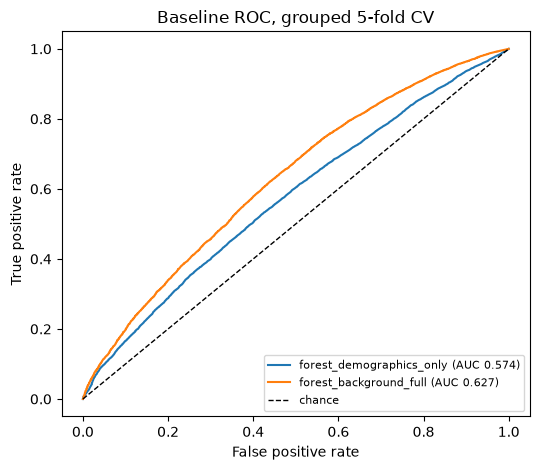

In [18]:
#ROC Curve Chart
fig, ax = plt.subplots(figsize=(5.5, 4.8))
for name in ["forest_demographics_only", "forest_background_full"]:
    fpr, tpr, _ = roc_curve(y, preds[name])
    ax.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y, preds[name]):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="chance")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("Baseline ROC, grouped 5-fold CV")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

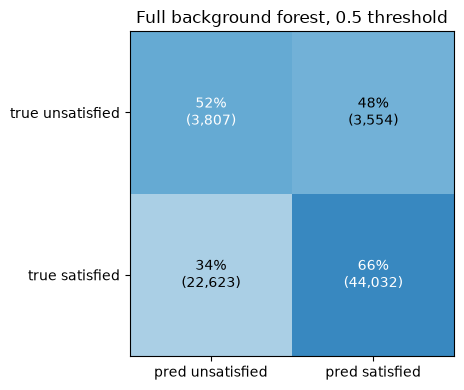

In [20]:
#Confusion Matrix
cm = confusion_matrix(y, (preds["forest_background_full"] >= 0.5).astype(int))
share = cm / cm.sum(axis=1, keepdims=True)          # each row sums to 100%
labels = ["unsatisfied", "satisfied"]
fig, ax = plt.subplots(figsize=(4.8, 4))
ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{share[i, j]:.0%}\n({cm[i, j]:,})", ha="center", va="center",
                color="white" if share[i, j] > 0.5 else "black")
ax.set_xticks([0, 1]); ax.set_xticklabels(["pred unsatisfied", "pred satisfied"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["true unsatisfied", "true satisfied"])
ax.set_title("Full background forest, 0.5 threshold")
plt.tight_layout(); plt.show()

**Part 6: Forest setting matter**

This only checks whether the conclusion depends on the leaf size we chose. Do not pick the best row and report it as the baseline, because that would tune on the evaluation folds.

In [16]:
def fast_forest(c, leaf):
    m = make_forest(c, leaf)
    m.set_params(clf__n_estimators=100)     
    return m

sensitivity = []
cols = FEATURE_SETS["background_full"]
for leaf in [100, 200, 500]:               
    p = predict(lambda c, leaf=leaf: fast_forest(c, leaf), cols)
    sensitivity.append({"min_samples_leaf": leaf, "roc_auc": round(roc_auc_score(y, p), 3),
                        "pr_auc_unsat": round(average_precision_score(1 - y, 1 - p), 3)})
sensitivity = pd.DataFrame(sensitivity)
sensitivity.to_csv("forest_leaf_sensitivity.csv", index=False)
sensitivity

,min_samples_leaf,roc_auc,pr_auc_unsat
0,100,0.626,0.161
1,200,0.627,0.161
2,500,0.626,0.158


**Part 8: Features that matter**

For each fold we shuffle one original column in the held-out data and measure how much ROC AUC drops. A big drop means the forest relies on that feature; a drop near zero (or negative) means it adds nothing. Values are averaged over the 5 folds. They show what the model uses, **not what causes dissatisfaction**.

In [17]:
cols = FEATURE_SETS["background_full"]
imp = np.zeros((len(folds), len(cols)))
for k, (tr, te) in enumerate(folds):
    m = make_forest(cols).fit(df.iloc[tr][cols], y[tr])
    pi = permutation_importance(m, df.iloc[te][cols], y[te], scoring="roc_auc",
                                n_repeats=10, random_state=SEED, n_jobs=-1)
    imp[k] = pi.importances_mean
importance = (pd.DataFrame({"feature": cols, "mean_auc_drop": imp.mean(axis=0), "sd_across_folds": imp.std(axis=0)})
              .sort_values("mean_auc_drop", ascending=False).round(4))
importance.to_csv("forest_permutation_importance.csv", index=False)
importance

,feature,mean_auc_drop,sd_across_folds
3,OCEDRLP,0.0718,0.0098
0,AGE,0.0364,0.0041
5,WAPRI,0.0043,0.0037
4,SUPWK,0.0040,0.0029
1,SEX_2023,0.0007,0.0010
2,DGRDG,0.0004,0.0016
